# PCN Overfitting Diagnostic

**Goal:** Verify that `PredictiveCodingNetwork` can *memorize* a tiny dataset.

A healthy model should drive train MSE near zero on 32 samples before we trust it on larger data. Two parts:
1. **Sanity / memorization check** — 32 train / 8 val / 8 test samples
2. **Scale check** — same architecture on 100 000 samples


## 0 — Imports & environment

In [55]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

# Locate repo root by walking upward until we find src/qvnn_pc
cwd = Path.cwd().resolve()
repo_root = next(path for path in [cwd, *cwd.parents] if (path / "src" / "qvnn_pc").exists())
src_path = repo_root / "src"
if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

torch.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Device : {device}")
print(f"PyTorch: {torch.__version__}")
print(f"Root   : {repo_root}")

Device : cuda
PyTorch: 2.11.0+cu130
Root   : /home/lukas/src/Sem4/OML/oml_fs2026/PCQVNN


---
## Part 1 — Memorization check (32 samples)
### 1.1 Data

In [56]:
from qvnn_pc.data import make_benchmark_regression_split
from qvnn_pc.models.pcn import PredictiveCodingNetwork

FUNCTION_NAME = "ackley"

split = make_benchmark_regression_split(
    FUNCTION_NAME,
    n=48,           # 48 * 2/3 = 32 train, 48 * 1/6 = 8 val, 8 test
    train_ratio=2 / 3,
    val_ratio=1 / 6,
    sample_seed=1,
    split_seed=2,
    device=None,
)

x_train = split.x_train[:, 0, :].to(device)
x_val   = split.x_val[:, 0, :].to(device)
x_test  = split.x_test[:, 0, :].to(device)
y_train = split.y_train_scalar.unsqueeze(-1).to(device)
y_val   = split.y_val_scalar.unsqueeze(-1).to(device)
y_test  = split.y_test_scalar.unsqueeze(-1).to(device)

assert x_train.shape[0] == 32, x_train.shape
assert x_val.shape[0]   ==  8, x_val.shape
assert x_test.shape[0]  ==  8, x_test.shape

print(f"Train : {tuple(x_train.shape)}  {tuple(y_train.shape)}")
print(f"Val   : {tuple(x_val.shape)}    {tuple(y_val.shape)}")
print(f"Test  : {tuple(x_test.shape)}   {tuple(y_test.shape)}")

Train : (32, 4)  (32, 1)
Val   : (8, 4)    (8, 1)
Test  : (8, 4)   (8, 1)


### 1.2 Standardize targets

We standardize `y` so all metrics (MSE, R²) are computed **in standardized space**.
This keeps loss values scale-independent and lets us compare across functions.
The original `y_train` / `y_val` values are kept for the final scatter plot.

In [57]:
# Fit scaler on train only — prevents val/test leakage
y_mean = y_train.mean(dim=0, keepdim=True)
y_std  = y_train.std(dim=0, keepdim=True).clamp_min(1e-8)

y_train_s = (y_train - y_mean) / y_std
y_val_s   = (y_val   - y_mean) / y_std
y_test_s  = (y_test  - y_mean) / y_std

print(f"y_mean={y_mean.item():.4f}  y_std={y_std.item():.4f}")
print(f"Standardized train y: mean={y_train_s.mean():.4f}  std={y_train_s.std():.4f}")

y_mean=20.9561  y_std=0.5746
Standardized train y: mean=0.0000  std=1.0000


### 1.3 Model & pre-training sanity probe

In [68]:
config = {
    "dims"            : [4, 20, 20, 20, 20],  # input_dim=4, four hidden layers of 20
    "output_dim"      : 1,
    "activation"      : "leakyrelu",
    "optimizer"       : "SGD",
    "epochs"          : 1000,
    "batch_size"      : 1,       # full-batch on 32 samples
    "eta_infer"       : 0.05,     # latent inference step size
    "eta_learn"       : 0.005,    # weight update step size
    "T_infer"         : 100,      # inference steps during training
    "T_learn"         : 32,       # weight update steps per batch
    "eval_infer_steps": 150,      # more steps at eval for tighter convergence
    "latent_init"     : "random",
}

model = PredictiveCodingNetwork(
    dims=config["dims"],
    output_dim=config["output_dim"],
    activation=config["activation"],
    optimizer=config["optimizer"],
    prediction_inference_steps=config["eval_infer_steps"],
    prediction_eta_infer=config["eta_infer"],
    device=device,
)

n_params = sum(p.numel() for p in model.parameters())
print(f"Parameters: {n_params}  (>{32}x the training set size — enough to memorize)")
print(pd.Series(config).to_string())

Parameters: 1300  (>32x the training set size — enough to memorize)
dims                [4, 20, 20, 20, 20]
output_dim                            1
activation                    leakyrelu
optimizer                           SGD
epochs                             1000
batch_size                            1
eta_infer                          0.05
eta_learn                         0.005
T_infer                             100
T_learn                              32
eval_infer_steps                    150
latent_init                      random


In [69]:
# Quick smoke-test: can the untrained model run a forward pass and evaluate?
probe_x = x_train[:8]
probe_y = y_train[:8]

probe_metrics_before = model.evaluate(
    probe_x, probe_y,
    infer_steps=25,
    eta_infer=config["eta_infer"],
    latent_init=config["latent_init"],
    return_trace=True,
)

print("Pre-training probe (untrained baseline):")
print(pd.Series({k: probe_metrics_before[k] for k in ["mse", "mae", "r2"]}).to_string())

Pre-training probe (untrained baseline):
mse    17.748913
mae     4.209352
r2    -26.300003


### 1.4 Training

In [70]:
history = model.fit(
    x_train, y_train_s,
    x_val=x_val,
    y_val=y_val_s,
    epochs=config["epochs"],
    batch_size=config["batch_size"],
    shuffle_generator=torch.Generator(device="cpu").manual_seed(1234),
    eta_infer=config["eta_infer"],
    eta_learn=config["eta_learn"],
    T_infer=config["T_infer"],
    T_learn=config["T_learn"],
    eval_infer_steps=config["eval_infer_steps"],
    latent_init=config["latent_init"],
)

print(f"Status      : {history['status']}")
print(f"Epochs ran  : {history['epochs_ran']}")
print(f"Runtime     : {history['runtime']:.2f}s")

Training PCN:   1%|▏         | 14/1000 [00:43<51:05,  3.11s/epoch]


KeyboardInterrupt: 

### 1.5 Clamped vs. test-mode inference

PCNs have **two inference modes** that produce different MSE values:

| Mode | What it does | When to use |
|------|-------------|-------------|
| **Label-clamped** | Fixes `y` and relaxes only hidden latents | During *training* — the model gets the answer |
| **Test-mode** (`predict`) | Relaxes *all* latents including the output | During *evaluation* — no answer provided |

Test-mode MSE is the number that actually matters for generalization.

In [ ]:
with torch.no_grad():
    # Label-clamped: y is fixed, only hidden latents are inferred
    clamped_out = model.infer_latents(
        x_train, y=y_train_s,
        steps=config["T_infer"],
        eta_infer=config["eta_infer"],
        latent_init=config["latent_init"],
    )
    mse_clamped = torch.mean((clamped_out["prediction"] - y_train_s) ** 2).item()

    # Test-mode: all latents free — this is what you get at inference time
    y_pred_test_mode = model.predict(
        x_train,
        infer_steps=config["eval_infer_steps"],
        eta_infer=config["eta_infer"],
        latent_init=config["latent_init"],
    )
    mse_test_mode = torch.mean((y_pred_test_mode - y_train_s) ** 2).item()

print(f"Label-clamped MSE : {mse_clamped:.6f}  (lower = model learned to reduce free energy)")
print(f"Test-mode MSE     : {mse_test_mode:.6f}  (← this is the true prediction quality)")

Label-clamped MSE : 0.000029  (lower = model learned to reduce free energy)
Test-mode MSE     : 0.946064  (← this is the true prediction quality)


### 1.6 Training curves

In [ ]:
metrics_df = pd.DataFrame({
    "epoch"    : range(1, history["epochs_ran"] + 1),
    "train_mse": history["mse"],
    "train_mae": history["mae"],
    "train_r2" : history["r2"],
    "val_mse"  : history["validation_mse"],
    "val_mae"  : history["validation_mae"],
    "val_r2"   : history["validation_r2"],
})

initial_train_mse = float(metrics_df["train_mse"].iloc[0])
final_train_mse   = float(metrics_df["train_mse"].iloc[-1])
final_val_mse     = float(metrics_df["val_mse"].iloc[-1])
final_train_r2    = float(metrics_df["train_r2"].iloc[-1])
final_val_r2      = float(metrics_df["val_r2"].iloc[-1])
improvement_pct   = (1 - final_train_mse / initial_train_mse) * 100

print("Last 10 epochs:")
display(metrics_df.tail(10))

print(f"\nInitial train MSE : {initial_train_mse:.6f}")
print(f"Final train MSE   : {final_train_mse:.6f}")
print(f"Final val MSE     : {final_val_mse:.6f}")
print(f"Train improvement : {improvement_pct:.2f}%")
print(f"Final train R²    : {final_train_r2:.4f}")
print(f"Final val R²      : {final_val_r2:.4f}")

Last 10 epochs:


,epoch,train_mse,train_mae,train_r2,val_mse,val_mae,val_r2
990,991,0.000016,0.002892,0.999983,0.000063,0.006789,0.999990
991,992,0.000017,0.002970,0.999983,0.000070,0.007124,0.999988
992,993,0.000018,0.003277,0.999981,0.000068,0.007217,0.999989
993,994,0.000016,0.002934,0.999984,0.000068,0.007069,0.999989
994,995,0.000017,0.002980,0.999983,0.000069,0.007066,0.999989
995,996,0.000017,0.002933,0.999983,0.000061,0.006753,0.999990
996,997,0.000015,0.002859,0.999985,0.000065,0.006986,0.999989
997,998,0.000021,0.003381,0.999979,0.000065,0.007138,0.999989
998,999,0.000016,0.002945,0.999984,0.000068,0.006884,0.999989
999,1000,0.000016,0.002891,0.999984,0.000062,0.006508,0.999990



Initial train MSE : 0.000074
Final train MSE   : 0.000016
Final val MSE     : 0.000062
Train improvement : 78.38%
Final train R²    : 1.0000
Final val R²      : 1.0000


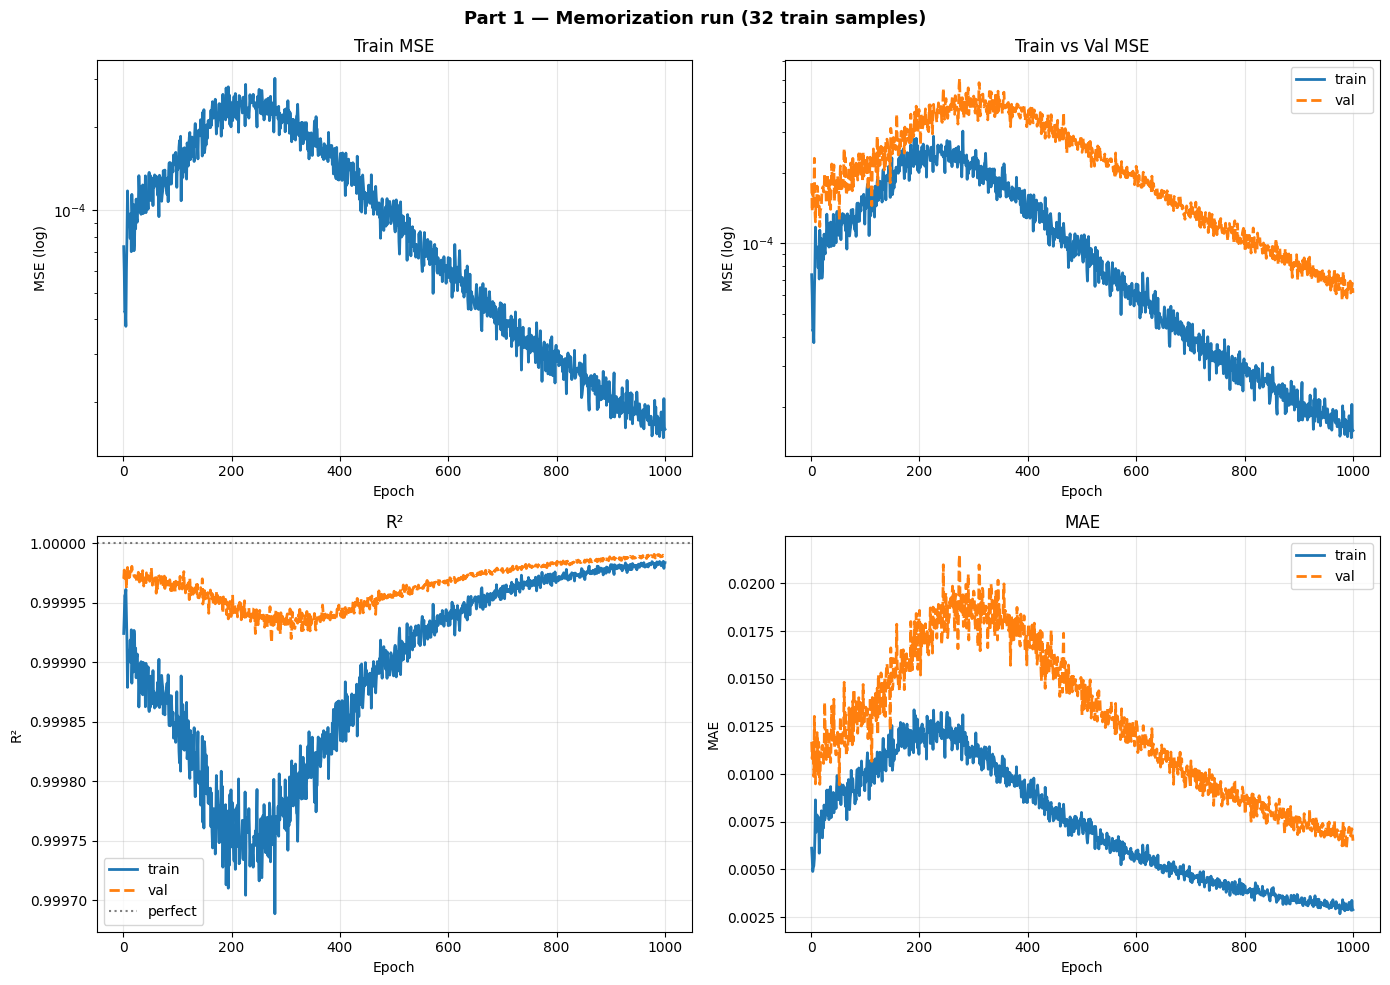

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Part 1 — Memorization run (32 train samples)", fontsize=13, fontweight="bold")

axes[0, 0].semilogy(metrics_df["epoch"], metrics_df["train_mse"], linewidth=2)
axes[0, 0].set(title="Train MSE", xlabel="Epoch", ylabel="MSE (log)")
axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].semilogy(metrics_df["epoch"], metrics_df["train_mse"], linewidth=2, label="train")
axes[0, 1].semilogy(metrics_df["epoch"], metrics_df["val_mse"], linestyle="--", linewidth=2, label="val")
axes[0, 1].set(title="Train vs Val MSE", xlabel="Epoch", ylabel="MSE (log)")
axes[0, 1].grid(True, alpha=0.3)
axes[0, 1].legend()

axes[1, 0].plot(metrics_df["epoch"], metrics_df["train_r2"], linewidth=2, label="train")
axes[1, 0].plot(metrics_df["epoch"], metrics_df["val_r2"], linestyle="--", linewidth=2, label="val")
axes[1, 0].axhline(1.0, color="black", linestyle=":", alpha=0.5, label="perfect")
axes[1, 0].set(title="R²", xlabel="Epoch", ylabel="R²")
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].legend()

axes[1, 1].plot(metrics_df["epoch"], metrics_df["train_mae"], linewidth=2, label="train")
axes[1, 1].plot(metrics_df["epoch"], metrics_df["val_mae"], linestyle="--", linewidth=2, label="val")
axes[1, 1].set(title="MAE", xlabel="Epoch", ylabel="MAE")
axes[1, 1].grid(True, alpha=0.3)
axes[1, 1].legend()

fig.tight_layout()
plt.show()

### 1.7 Overfitting diagnosis

In [ ]:
passes, issues = [], []

if history["status"] != "completed":
    issues.append(f"Training ended early: status={history['status']}")
if improvement_pct > 90:
    passes.append(f"Strong train-loss reduction ({improvement_pct:.1f}%)")
else:
    issues.append(f"Weak train-loss reduction ({improvement_pct:.1f}%)")
if final_train_mse < 1e-2:
    passes.append(f"Train MSE near zero ({final_train_mse:.6f})")
else:
    issues.append(f"Train MSE still high ({final_train_mse:.6f})")
if final_train_r2 > 0.95:
    passes.append(f"Train R² excellent ({final_train_r2:.4f})")
else:
    issues.append(f"Train R² too low for memorization ({final_train_r2:.4f})")

print("=== MEMORIZATION DIAGNOSIS ===\n")
for item in passes:  print(f"  PASS  : {item}")
for item in issues:  print(f"  ISSUE : {item}")

print()
if issues:
    print("Conclusion: PCN cannot yet memorize this tiny set — architecture or hyperparams need tuning.")
else:
    print("Conclusion: PCN memorized the training set. ✓")

=== MEMORIZATION DIAGNOSIS ===

  PASS  : Train MSE near zero (0.000016)
  PASS  : Train R² excellent (1.0000)
  ISSUE : Weak train-loss reduction (78.4%)

Conclusion: PCN cannot yet memorize this tiny set — architecture or hyperparams need tuning.


### 1.8 Prediction scatter: true vs. predicted

> **Why the scatter might not be on the perfect diagonal even when R² = 1.0000:**  
> The metrics (MSE, R²) logged during training are computed in **standardized space** (zero-mean, unit-variance).  
> The scatter below uses `model(x)` — the *fast forward pass* — which does **one** feed-forward sweep, not a full inference loop.  
> The full inference loop (used for metrics) runs up to `eval_infer_steps=150` gradient steps on the latent variables, reaching a much better optimum.  
> To see the same quality as the metrics, use `model.predict(...)` instead of `model(...)`.  
> Additionally, the scatter is in **original scale** while metrics are standardized — large `y_std` amplifies any residual error visually.

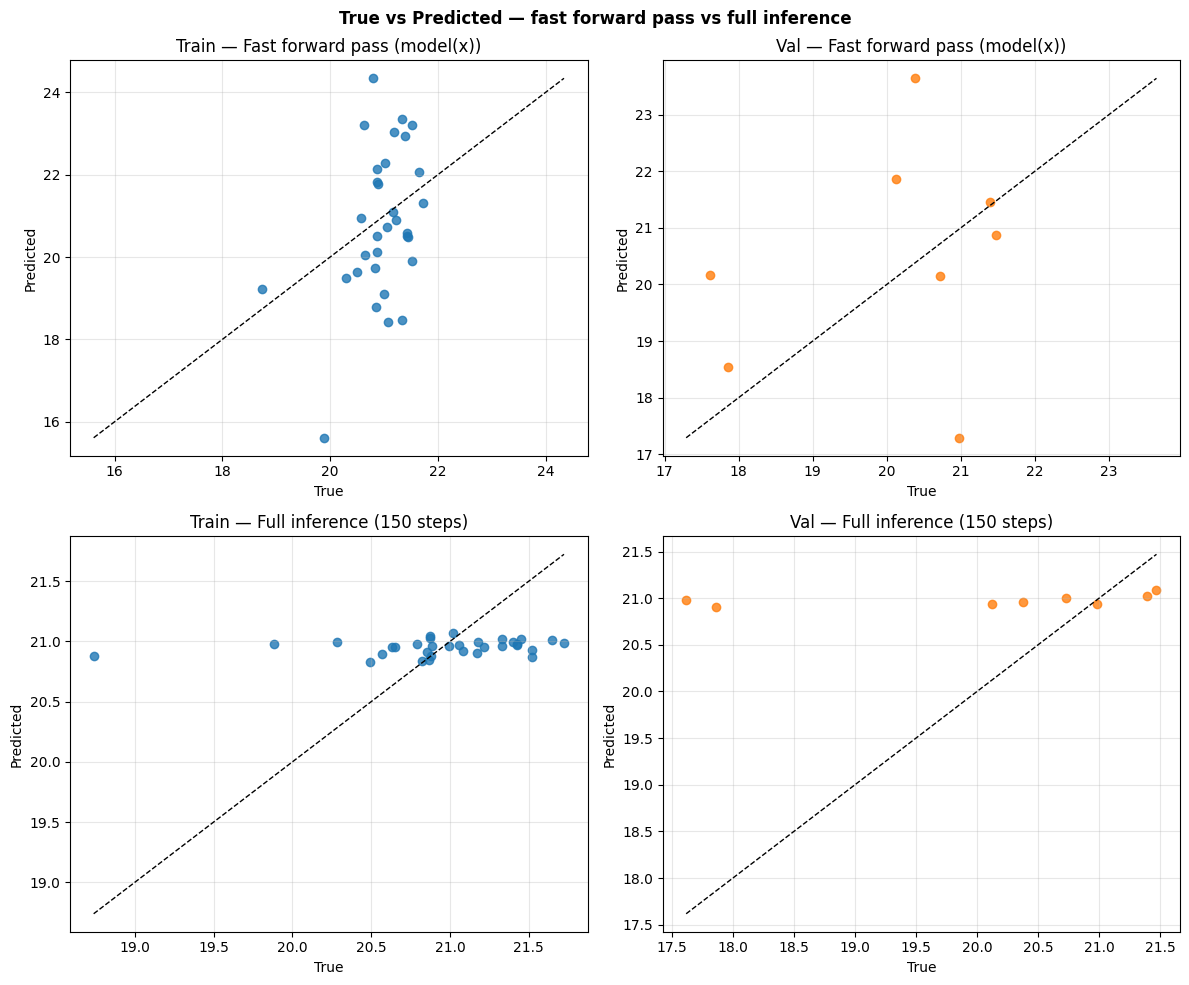

In [ ]:
with torch.no_grad():
    # Fast forward pass — no iterative inference, just one sweep through the weights
    y_train_pred_fast = model(x_train).cpu().numpy().squeeze(-1)
    y_val_pred_fast   = model(x_val).cpu().numpy().squeeze(-1)

    # Proper test-mode inference — iterative relaxation, same as eval metrics
    y_train_pred_full = model.predict(
        x_train,
        infer_steps=config["eval_infer_steps"],
        eta_infer=config["eta_infer"],
        latent_init=config["latent_init"],
    ).cpu().numpy().squeeze(-1)
    
    y_val_pred_full = model.predict(
        x_val,
        infer_steps=config["eval_infer_steps"],
        eta_infer=config["eta_infer"],
        latent_init=config["latent_init"],
    ).cpu().numpy().squeeze(-1)

# Denormalise for interpretable original-scale scatter
mu  = y_mean.cpu().numpy().squeeze()
sig = y_std.cpu().numpy().squeeze()

y_train_pred_fast_orig = y_train_pred_fast * sig + mu
y_val_pred_fast_orig   = y_val_pred_fast   * sig + mu
y_train_pred_full_orig = y_train_pred_full * sig + mu
y_val_pred_full_orig   = y_val_pred_full   * sig + mu

train_true = y_train.cpu().numpy().squeeze(-1)
val_true   = y_val.cpu().numpy().squeeze(-1)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle("True vs Predicted — fast forward pass vs full inference", fontsize=12, fontweight="bold")

for row, (preds_tr, preds_val, label) in enumerate([
    (y_train_pred_fast_orig, y_val_pred_fast_orig, "Fast forward pass (model(x))"),
    (y_train_pred_full_orig, y_val_pred_full_orig, f"Full inference ({config['eval_infer_steps']} steps)"),
]):
    for col, (true, pred, split_label, color) in enumerate([
        (train_true, preds_tr, "Train", "tab:blue"),
        (val_true,   preds_val, "Val",   "tab:orange"),
    ]):
        ax = axes[row, col]
        ax.scatter(true, pred, alpha=0.8, color=color)
        lims = [min(true.min(), pred.min()), max(true.max(), pred.max())]
        ax.plot(lims, lims, "k--", linewidth=1, label="perfect")
        ax.set(title=f"{split_label} — {label}", xlabel="True", ylabel="Predicted")
        ax.grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

---
## Part 2 — Scale check (100 000 samples)

Same architecture, much more data. Goal: confirm the model learns meaningful structure (not just memorizes).

### 2.1 Data

In [ ]:
split_big = make_benchmark_regression_split(
    FUNCTION_NAME,
    n=100_000,
    train_ratio=0.70,
    val_ratio=0.15,
    sample_seed=1,
    split_seed=2,
    device=device,
)

x_train_2 = split_big.x_train[:, 0, :]
x_val_2   = split_big.x_val[:, 0, :]
x_test_2  = split_big.x_test[:, 0, :]
y_train_2 = split_big.y_train_scalar.unsqueeze(-1)
y_val_2   = split_big.y_val_scalar.unsqueeze(-1)
y_test_2  = split_big.y_test_scalar.unsqueeze(-1)

# Standardize (fit on train only)
y_mean_2 = y_train_2.mean(dim=0, keepdim=True)
y_std_2  = y_train_2.std(dim=0, keepdim=True).clamp_min(1e-8)

y_train_s_2 = (y_train_2 - y_mean_2) / y_std_2
y_val_s_2   = (y_val_2   - y_mean_2) / y_std_2
y_test_s_2  = (y_test_2  - y_mean_2) / y_std_2

print(f"Train: {tuple(x_train_2.shape)}")
print(f"Val  : {tuple(x_val_2.shape)}")
print(f"Test : {tuple(x_test_2.shape)}")

Train: (70000, 4)
Val  : (15000, 4)
Test : (15000, 4)


### 2.2 Model & training

In [ ]:
config_full = {
    "dims"            : [4, 20, 20, 20, 20],
    "output_dim"      : 1,
    "activation"      : "leakyrelu",
    "optimizer"       : "SGD",
    "epochs"          : 100,
    "batch_size"      : 512,
    "eta_infer"       : 0.05,
    "eta_learn"       : 0.005,
    "T_infer"         : 100,
    "T_learn"         : 25,
    "eval_infer_steps": 150,
    "latent_init"     : "random",
}

model_full = PredictiveCodingNetwork(
    dims=config_full["dims"],
    output_dim=config_full["output_dim"],
    activation=config_full["activation"],
    optimizer=config_full["optimizer"],
    prediction_inference_steps=config_full["eval_infer_steps"],
    prediction_eta_infer=config_full["eta_infer"],
    device=device,
)

history_full = model_full.fit(
    x_train_2, y_train_s_2,
    x_val=x_val_2,
    y_val=y_val_s_2,
    epochs=config_full["epochs"],
    batch_size=config_full["batch_size"],
    shuffle_generator=torch.Generator(device="cpu").manual_seed(1234),
    eta_infer=config_full["eta_infer"],
    eta_learn=config_full["eta_learn"],
    T_infer=config_full["T_infer"],
    T_learn=config_full["T_learn"],
    eval_infer_steps=config_full["eval_infer_steps"],
    latent_init=config_full["latent_init"],
)

print(f"Status : {history_full['status']}")
print(f"Epochs : {history_full['epochs_ran']}")
print(f"Runtime: {history_full['runtime']:.2f}s")

Training PCN:  57%|█████▋    | 57/100 [12:06<09:08, 12.75s/epoch]


KeyboardInterrupt: 

### 2.3 Clamped vs. test-mode (scale run)

In [ ]:
with torch.no_grad():
    clamped_out_2 = model_full.infer_latents(
        x_train_2, y=y_train_s_2,
        steps=config_full["T_infer"],
        eta_infer=config_full["eta_infer"],
        latent_init=config_full["latent_init"],
    )
    mse_clamped_2  = torch.mean((clamped_out_2["prediction"] - y_train_s_2) ** 2).item()

    y_pred_full_2  = model_full.predict(
        x_train_2,
        infer_steps=config_full["eval_infer_steps"],
        eta_infer=config_full["eta_infer"],
        latent_init=config_full["latent_init"],
    )
    mse_test_2 = torch.mean((y_pred_full_2 - y_train_s_2) ** 2).item()

print(f"Label-clamped MSE : {mse_clamped_2:.6f}")
print(f"Test-mode MSE     : {mse_test_2:.6f}")

### 2.4 Training curves

In [ ]:
metrics_df_full = pd.DataFrame({
    "epoch"    : range(1, history_full["epochs_ran"] + 1),
    "train_mse": history_full["mse"],
    "train_mae": history_full["mae"],
    "train_r2" : history_full["r2"],
    "val_mse"  : history_full["validation_mse"],
    "val_mae"  : history_full["validation_mae"],
    "val_r2"   : history_full["validation_r2"],
})

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Part 2 — Scale run (100 000 samples)", fontsize=13, fontweight="bold")

axes[0, 0].semilogy(metrics_df_full["epoch"], metrics_df_full["train_mse"], linewidth=2)
axes[0, 0].set(title="Train MSE", xlabel="Epoch", ylabel="MSE (log)")
axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].semilogy(metrics_df_full["epoch"], metrics_df_full["train_mse"], linewidth=2, label="train")
axes[0, 1].semilogy(metrics_df_full["epoch"], metrics_df_full["val_mse"], linestyle="--", linewidth=2, label="val")
axes[0, 1].set(title="Train vs Val MSE", xlabel="Epoch", ylabel="MSE (log)")
axes[0, 1].grid(True, alpha=0.3)
axes[0, 1].legend()

axes[1, 0].plot(metrics_df_full["epoch"], metrics_df_full["train_r2"], linewidth=2, label="train")
axes[1, 0].plot(metrics_df_full["epoch"], metrics_df_full["val_r2"], linestyle="--", linewidth=2, label="val")
axes[1, 0].axhline(1.0, color="black", linestyle=":", alpha=0.5, label="perfect")
axes[1, 0].set(title="R²", xlabel="Epoch", ylabel="R²")
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].legend()

axes[1, 1].plot(metrics_df_full["epoch"], metrics_df_full["train_mae"], linewidth=2, label="train")
axes[1, 1].plot(metrics_df_full["epoch"], metrics_df_full["val_mae"], linestyle="--", linewidth=2, label="val")
axes[1, 1].set(title="MAE", xlabel="Epoch", ylabel="MAE")
axes[1, 1].grid(True, alpha=0.3)
axes[1, 1].legend()

fig.tight_layout()
plt.show()

### 2.5 Prediction scatter (scale run)

**Note:** uses `model_full.predict(...)` (full inference) for a fair comparison with the logged metrics.  
On 100 k samples this is slow — subsample if needed.

In [ ]:
N_SCATTER = 2000  # cap points so the plot stays readable and fast

idx_tr = torch.randperm(x_train_2.shape[0])[:N_SCATTER]
idx_vl = torch.randperm(x_val_2.shape[0])[:N_SCATTER]

with torch.no_grad():
    # Full inference so this is directly comparable to the logged metrics
    y_tr_pred_2 = model_full.predict(
        x_train_2[idx_tr],
        infer_steps=config_full["eval_infer_steps"],
        eta_infer=config_full["eta_infer"],
        latent_init=config_full["latent_init"],
    ).cpu().numpy().squeeze(-1)
    y_vl_pred_2 = model_full.predict(
        x_val_2[idx_vl],
        infer_steps=config_full["eval_infer_steps"],
        eta_infer=config_full["eta_infer"],
        latent_init=config_full["latent_init"],
    ).cpu().numpy().squeeze(-1)

mu2  = y_mean_2.cpu().numpy().squeeze()
sig2 = y_std_2.cpu().numpy().squeeze()

y_tr_pred_orig = y_tr_pred_2 * sig2 + mu2
y_vl_pred_orig = y_vl_pred_2 * sig2 + mu2
tr_true = y_train_2[idx_tr].cpu().numpy().squeeze(-1)
vl_true = y_val_2[idx_vl].cpu().numpy().squeeze(-1)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle(f"True vs Predicted (full inference, n={N_SCATTER} each)", fontsize=12, fontweight="bold")

for ax, true, pred, label, color in [
    (axes[0], tr_true, y_tr_pred_orig, "Train", "tab:blue"),
    (axes[1], vl_true, y_vl_pred_orig, "Val",   "tab:orange"),
]:
    ax.scatter(true, pred, alpha=0.4, s=15, color=color)
    lims = [min(true.min(), pred.min()), max(true.max(), pred.max())]
    ax.plot(lims, lims, "k--", linewidth=1)
    ax.set(title=f"{label} predictions", xlabel="True", ylabel="Predicted")
    ax.grid(True, alpha=0.3)

fig.tight_layout()
plt.show()